In [15]:
import zipfile

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(r'D:\dataset')


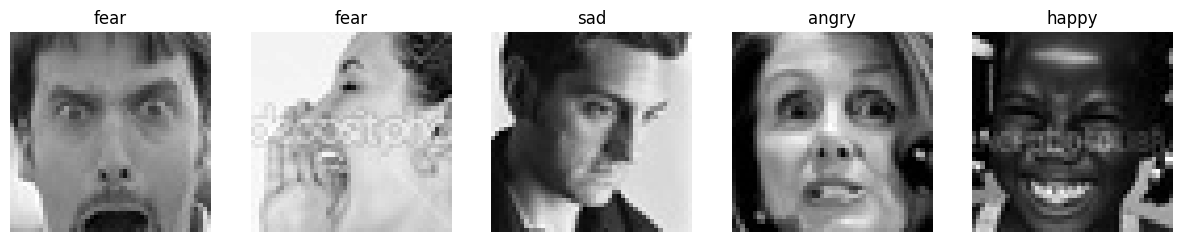

In [16]:
import os
import random
import matplotlib.pyplot as plt
from PIL import Image

# Папка с датасетом (train/test/validation)
base_folder = r'D:\dataset\train'

# Получаем все подпапки (каждая папка — это эмоция)
emotion_folders = [os.path.join(base_folder, f) for f in os.listdir(base_folder)
                   if os.path.isdir(os.path.join(base_folder, f))]

# Словарь меток эмоций (если нужно)
emotion_labels = {
    "0": "Angry",
    "1": "Disgust",
    "2": "Fear",
    "3": "Happy",
    "4": "Sad",
    "5": "Surprise",
    "6": "Neutral"
}

# Случайно выбираем несколько изображений для показа
num_images = 5
plt.figure(figsize=(15, 5))

for i in range(num_images):
    # случайная папка с эмоцией
    folder = random.choice(emotion_folders)
    # случайное изображение из папки
    filename = random.choice(os.listdir(folder))
    img_path = os.path.join(folder, filename)
    
    # открываем изображение
    img = Image.open(img_path)
    
    # выводим на экран
    plt.subplot(1, num_images, i+1)
    plt.imshow(img, cmap='gray')
    plt.title(emotion_labels.get(os.path.basename(folder), os.path.basename(folder)))
    plt.axis('off')
%matplotlib inline
plt.show()


In [17]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Папки с данными (поменяй пути на свои)
train_dir = r'D:\dataset\train'
val_dir = r'D:\dataset\test'

# 1️⃣ Подготовка данных
train_datagen = ImageDataGenerator(rescale=1./255)
val_datagen = ImageDataGenerator(rescale=1./255)

train_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=(48, 48),
    color_mode='grayscale',
    batch_size=64,
    class_mode='categorical'
)

val_generator = val_datagen.flow_from_directory(
    val_dir,
    target_size=(48, 48),
    color_mode='grayscale',
    batch_size=64,
    class_mode='categorical'
)

# 2️⃣ Создание простой нейросети (CNN)
model = Sequential([
    Conv2D(32, (3,3), activation='relu', input_shape=(48,48,1)),
    MaxPooling2D(2,2),
    Conv2D(64, (3,3), activation='relu'),
    MaxPooling2D(2,2),
    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.5),
    Dense(7, activation='softmax')  # 7 эмоций
])

# 3️⃣ Компиляция модели
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# 4️⃣ Обучение модели
history = model.fit(
    train_generator,
    epochs=10,
    validation_data=val_generator
)

# 5️⃣ Сохранение модели
model.save('emotion_model.h5')


Found 28709 images belonging to 7 classes.
Found 7178 images belonging to 7 classes.


C:\Users\pc\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
C:\Users\pc\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/10
449/449 ━━━━━━━━━━━━━━━━━━━━ 27s 58ms/step - accuracy: 0.3200 - loss: 1.7039 - val_accuracy: 0.4253 - val_loss: 1.5246
Epoch 2/10
449/449 ━━━━━━━━━━━━━━━━━━━━ 25s 55ms/step - accuracy: 0.4132 - loss: 1.5157 - val_accuracy: 0.4613 - val_loss: 1.4027
Epoch 3/10
449/449 ━━━━━━━━━━━━━━━━━━━━ 27s 59ms/step - accuracy: 0.4461 - loss: 1.4338 - val_accuracy: 0.4823 - val_loss: 1.3611
Epoch 4/10
449/449 ━━━━━━━━━━━━━━━━━━━━ 25s 56ms/step - accuracy: 0.4688 - loss: 1.3828 - val_accuracy: 0.4926 - val_loss: 1.3269
Epoch 5/10
449/449 ━━━━━━━━━━━━━━━━━━━━ 27s 60ms/step - accuracy: 0.4927 - loss: 1.3253 - val_accuracy: 0.4946 - val_loss: 1.3023
Epoch 6/10
449/449 ━━━━━━━━━━━━━━━━━━━━ 26s 59ms/step - accuracy: 0.5098 - loss: 1.2846 - val_accuracy: 0.5053 - val_loss: 1.2706
Epoch 7/10
449/449 ━━━━━━━━━━━━━━━━━━━━ 25s 56ms/step - accuracy: 0.5304 - loss: 1.2359 - val_accuracy: 0.5217 - val_loss: 1.2435
Epoch 8/10
449/449 ━━━━━━━━━━━━━━━━━━━━ 27s 60ms/step - accuracy: 0.5466 - loss: 1.1910 - 

In [29]:
import cv2
import numpy as np
from tensorflow.keras.models import load_model

# Загрузка обученной модели
model = load_model('emotion_model.h5')

# Категории эмоций (по FER2013)
emotion_labels = ['Angry', 'Disgust', 'Fear', 'Happy', 'Sad', 'Surprise', 'Neutral']

# Загрузка изображения
img_path = r'C:\Users\pc\Downloads\log1.jpeg'  # 🔹 Укажи путь к своему фото
img = cv2.imread(img_path)

# Преобразование в оттенки серого
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Изменяем размер под формат FER2013 — 48x48
face = cv2.resize(gray, (48, 48))
face = face / 255.0  # нормализация
face = np.expand_dims(face, axis=(0, -1))  # добавляем размерности

# Предсказание эмоции
prediction = model.predict(face)
emotion = emotion_labels[np.argmax(prediction)]

print("Распознанная эмоция:", emotion)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step
Распознанная эмоция: Fear
